# 🏭 Production Line Digital Twin — Part 4: What-If Scenarios
We use the digital twin to test improvement ideas **before spending real money**:
1. Baseline (current line)
2. Buy a second welder
3. Buy a faster welder
4. Preventive maintenance
5. Faster repairs (bigger maintenance team)
6. Second welder + preventive maintenance

Each scenario runs 5 times with different random seeds, and we compare the averages.

### Imports
`copy` is used to make independent copies of the settings dictionary.

In [1]:
import simpy
import random
import copy                        # to make independent copies of our settings
import os
import pandas as pd
import matplotlib.pyplot as plt

### Baseline settings and `make_scenario`
All settings live in one dictionary, so a scenario is just a modified copy of it.

- `pm_threshold`: do preventive maintenance (PM) when health drops below this value. `0` means never, since health is never below 0.
- `make_scenario(**changes)` deep-copies the baseline (so the nested dicts aren't shared) and then:
  - **merges** dict values: `machines={"Welding": 2}` changes Welding only
  - **replaces** everything else.

In [2]:
# All settings live in ONE dictionary, so a scenario = a changed copy of this dictionary
BASELINE = {
    "sim_time":         10 * 8 * 60,     # 10 shifts = 4800 minutes
    "arrival_interval": 5,               # a new part every ~5 minutes
    "process_times":    {"Cutting": 4, "Welding": 6, "Painting": 5, "Inspection": 3},
    "machines":         {"Cutting": 1, "Welding": 1, "Painting": 1, "Inspection": 1},
    "repair_time":      (20, 40),        # breakdown repair takes 20–40 minutes
    "pm_threshold":     0,               # do PM when health drops below this. 0 = never do PM
    "pm_time":          10,              # a preventive maintenance takes 10 minutes
}

def make_scenario(**changes):
    """
    Copy the baseline and change only what we list.
    Example: make_scenario(machines={"Welding": 2}) changes ONLY the welding machine count.
    """
    config = copy.deepcopy(BASELINE)            # deepcopy = a fully independent copy
    for key, value in changes.items():
        if isinstance(value, dict):
            config[key].update(value)           # update only the stations we mention
        else:
            config[key] = value
    return config

### Machine and Station classes
**Machine:** same wear as Part 2 (about −1 health per part), but these probability formulas are used:

$$p_{fail} = 0.002 + 0.05 \cdot \frac{100 - h}{100} \quad (0.2\% \text{ new} \rightarrow 5.2\% \text{ worn, linear})$$

$$p_{def} = 0.0005 + 0.2 \left(\frac{100 - h}{100}\right)^3 \quad (0.05\% \text{ new} \rightarrow 20\% \text{ worn, cubic})$$

> ⚠️ Not the same as Part 2: there, failure was cubic and defect was linear.

**Station:** can hold several identical machines. `simpy.Resource(capacity=n)` lets $n$ parts be processed at once from **one shared queue**. `get_free_machine()` returns the first idle machine.

In [3]:
class Machine:
    """One physical machine. Same wear as Step 2, but different failure/defect formulas."""

    def __init__(self, name):
        self.name = name
        self.health = 100.0
        self.status = "idle"            # "idle", "running", "broken", "maintenance"

    def wear_out(self):
        self.health = max(self.health - random.uniform(0.5, 1.5), 0)

    def failure_probability(self):
        return 0.002 + (100 - self.health) / 100 * 0.05

    def defect_probability(self):
        return 0.0005 + ((100 - self.health) / 100) ** 3 * 0.2


class Station:
    """
    A station (like "Welding") can now have SEVERAL identical machines.
    Parts wait in ONE shared queue and take whichever machine is free.
    """

    def __init__(self, env, name, avg_time, n_machines):
        self.name = name
        self.avg_time = avg_time
        self.resource = simpy.Resource(env, capacity=n_machines)   # n parts can be processed at once
        self.machines = [Machine(f"{name}-{i + 1}") for i in range(n_machines)]

    def get_free_machine(self):
        """Return the first machine that is idle."""
        for machine in self.machines:
            if machine.status == "idle":
                return machine

### Repair vs preventive maintenance
| | Repair (unplanned) | PM (planned) |
|---|---|---|
| Trigger | random breakdown | health < `pm_threshold` |
| Duration | $\sim \text{Uniform}(20, 40)$, mean 30 min | fixed 10 min |
| Result | health → 100 | health → 100 |

PM trades a short, predictable stop for avoiding a long, random one. `*config["repair_time"]` unpacks `(20, 40)` into two arguments.

In [4]:
def repair(env, station, machine, logs, config):
    """Unplanned: the machine BROKE. Slow and expensive."""
    machine.status = "broken"
    repair_time = random.uniform(*config["repair_time"])     # * unpacks (20, 40) into 20, 40
    logs["failures"].append({"station": station.name, "machine": machine.name,
                             "failure_time": env.now, "repair_time": repair_time})
    yield env.timeout(repair_time)
    machine.health = 100.0


def preventive_maintenance(env, station, machine, logs, config):
    """Planned: we service the machine BEFORE it breaks. Short and predictable."""
    machine.status = "maintenance"
    logs["maintenance"].append({"station": station.name, "machine": machine.name,
                                "start_time": env.now, "duration": config["pm_time"]})
    yield env.timeout(config["pm_time"])
    machine.health = 100.0

### Part journey and generator
Same flow as Part 2, with one change after processing:
1. if the machine breaks → **repair**
2. otherwise, if health < threshold → **PM**

Both hold the machine, so the queue waits.

In [5]:
def part(env, part_id, stations, logs, config):
    for station in stations.values():
        arrival_time = env.now

        with station.resource.request() as request:
            yield request                              # wait for ANY free machine at this station
            machine = station.get_free_machine()       # pick which machine we got
            machine.status = "running"
            start_time = env.now

            process_time = random.uniform(station.avg_time * 0.8, station.avg_time * 1.2)
            yield env.timeout(process_time)

            defect = random.random() < machine.defect_probability()
            machine.wear_out()

            # First: did it break? If not, is it worn enough for planned maintenance?
            if random.random() < machine.failure_probability():
                yield env.process(repair(env, station, machine, logs, config))
            elif machine.health < config["pm_threshold"]:
                yield env.process(preventive_maintenance(env, station, machine, logs, config))

            machine.status = "idle"
            end_time = env.now

        logs["production"].append({
            "part_id": part_id, "station": station.name,
            "arrival_time": arrival_time, "start_time": start_time,
            "end_time": end_time, "defect": defect,
        })


def part_generator(env, stations, logs, config):
    part_id = 0
    while True:
        yield env.timeout(random.expovariate(1 / config["arrival_interval"]))
        part_id += 1
        env.process(part(env, part_id, stations, logs, config))

### KPI calculation
A condensed version of Part 3:

$$\text{good parts/shift} = \frac{\text{good parts}}{\text{sim time} / 480} \qquad \text{yield} = \frac{\text{good}}{\text{finished}} \times 100$$

Lead time, WIP and repair downtime (clipped at the end of the simulation) are calculated as in Part 3. First and last station names come from the config, so this works for any line.

In [6]:
def calculate_kpis(logs, config):
    production = pd.DataFrame(logs["production"])
    failures   = pd.DataFrame(logs["failures"],
                              columns=["station", "machine", "failure_time", "repair_time"])

    sim_time = config["sim_time"]
    shifts = sim_time / 480
    station_names = list(config["process_times"])
    first, last = station_names[0], station_names[-1]

    # One row per finished part
    finished = production[production["station"] == last][["part_id", "end_time"]]
    entered  = production[production["station"] == first][["part_id", "arrival_time"]]
    parts = finished.merge(entered, on="part_id")

    defective_ids = production.loc[production["defect"], "part_id"].unique()
    good_parts = (~parts["part_id"].isin(defective_ids)).sum()

    # Repair downtime, cut off at the end of the simulation
    repair_end = (failures["failure_time"] + failures["repair_time"]).clip(upper=sim_time)
    downtime = (repair_end - failures["failure_time"]).sum()

    return {
        "good_parts_per_shift": good_parts / shifts,
        "yield_%":              good_parts / len(parts) * 100,
        "avg_lead_time_min":    (parts["end_time"] - parts["arrival_time"]).mean(),
        "wip_at_end":           entered["part_id"].nunique() - len(parts),
        "failures":             len(failures),
        "repair_downtime_min":  downtime,
        "pm_count":             len(logs["maintenance"]),
    }

### The digital twin in one function
`run_simulation(config, seed)` builds the stations from the config, runs the simulation and returns a dict of KPIs. Any scenario is now one function call.

In [7]:
def run_simulation(config, seed=42):
    """Build the factory from 'config', run it, and return its KPIs."""
    random.seed(seed)
    env = simpy.Environment()

    stations = {
        name: Station(env, name, avg_time, config["machines"][name])
        for name, avg_time in config["process_times"].items()
    }
    logs = {"production": [], "failures": [], "maintenance": []}

    env.process(part_generator(env, stations, logs, config))
    env.run(until=config["sim_time"])

    return calculate_kpis(logs, config)


# Quick test: run the baseline once
test = run_simulation(BASELINE)
for kpi, value in test.items():
    print(f"{kpi:22s} {value:.1f}")

good_parts_per_shift   66.0
yield_%                89.8
avg_lead_time_min      621.4
wip_at_end             243.0
failures               54.0
repair_downtime_min    1640.9
pm_count               0.0


### Average over several seeds
A single run depends on luck. Each scenario is run with 5 seeds and the average is taken:

$$\overline{KPI} = \frac{1}{5}\sum_{s=1}^{5} KPI_s$$

In [8]:
SEEDS = [1, 2, 3, 4, 5]

def run_scenario(config, seeds=SEEDS):
    """Run the same scenario with different random seeds and return the AVERAGE KPIs."""
    results = [run_simulation(config, seed) for seed in seeds]
    return pd.DataFrame(results).mean()     # average of each KPI column

### The scenarios
| # | Change | Why it could help |
|---|---|---|
| 2 | 2 welders | effective $6/2 = 3$ min/part, so Welding is no longer the bottleneck |
| 3 | welding 4.5 min | $\rho = 4.5/5 = 0.9 < 1$, so the queue stops growing |
| 4 | PM at health 60 | fixes machines before they break |
| 5 | repair 10–20 min | shorter downtime per breakdown |
| 6 | 2 + 4 combined | |

In [9]:
scenarios = {
    "1. Baseline":               make_scenario(),
    "2. Second welder":          make_scenario(machines={"Welding": 2}),
    "3. Faster welder (4.5min)": make_scenario(process_times={"Welding": 4.5}),
    "4. Preventive maintenance": make_scenario(pm_threshold=60),
    "5. Faster repairs":         make_scenario(repair_time=(10, 20)),
    "6. 2nd welder + PM":        make_scenario(machines={"Welding": 2}, pm_threshold=60),
}

### Run all scenarios
6 scenarios × 5 seeds = 30 simulations. `.T` transposes the table so there's one row per scenario.

$$\text{vs baseline (\%)} = \left(\frac{\text{good/shift}_{\text{scenario}}}{\text{good/shift}_{\text{baseline}}} - 1\right) \times 100$$

In [10]:
# This runs 6 scenarios × 5 seeds = 30 simulations (should take a few seconds)
results = pd.DataFrame({name: run_scenario(cfg) for name, cfg in scenarios.items()}).T

# How much better or worse than the baseline? (in %)
baseline_good = results.loc["1. Baseline", "good_parts_per_shift"]
results["vs_baseline_%"] = (results["good_parts_per_shift"] / baseline_good - 1) * 100

results = results.round(1)
results

,good_parts_per_shift,yield_%,avg_lead_time_min,wip_at_end,failures,repair_downtime_min,pm_count,vs_baseline_%
1. Baseline,67.2,91.5,542.4,207.0,57.8,1706.3,0.0,0.0
2. Second welder,78.4,92.5,289.4,110.8,69.8,2044.1,0.0,16.6
3. Faster welder (4.5min),78.8,93.0,263.7,97.0,66.6,1989.4,0.0,17.3
4. Preventive maintenance,72.6,98.6,583.5,210.0,35.0,1034.7,55.4,8.0
5. Faster repairs,70.1,92.5,516.7,201.4,63.0,936.0,0.0,4.3
6. 2nd welder + PM,85.4,98.6,275.5,92.0,42.4,1259.8,61.2,27.0


### Compare the scenarios visually
The dashed line marks the baseline. Bars to the right of it on the left chart are improvements.

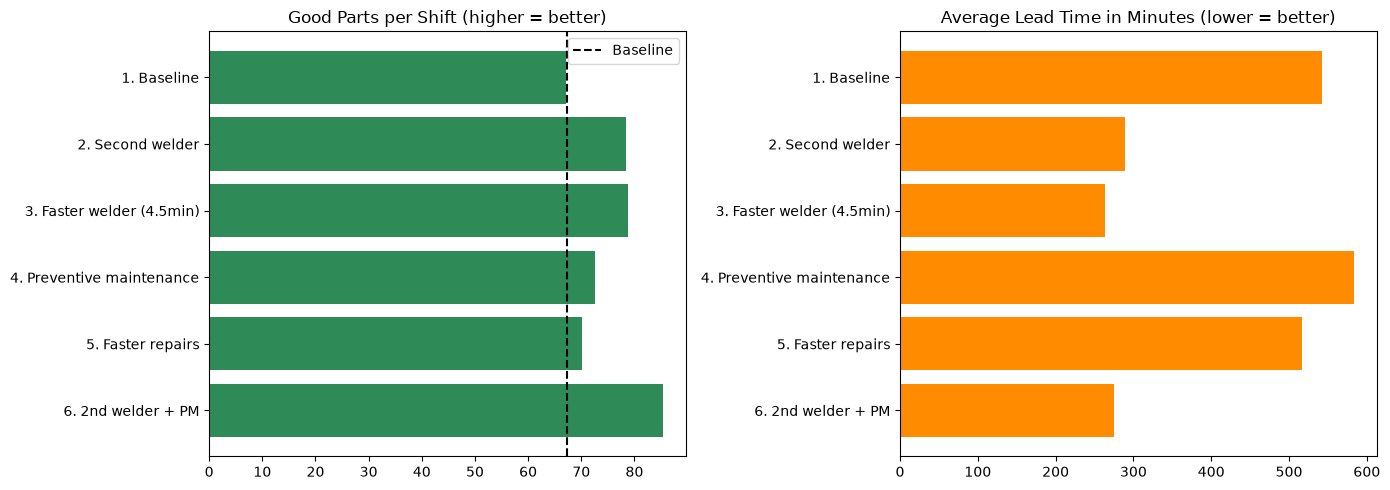

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: good parts per shift (higher = better)
ax = axes[0]
ax.barh(results.index, results["good_parts_per_shift"], color="seagreen")
ax.axvline(baseline_good, color="black", linestyle="--", label="Baseline")
ax.set_title("Good Parts per Shift (higher = better)")
ax.invert_yaxis()                       # scenario 1 at the top
ax.legend()

# Right: average lead time (lower = better)
ax = axes[1]
ax.barh(results.index, results["avg_lead_time_min"], color="darkorange")
ax.set_title("Average Lead Time in Minutes (lower = better)")
ax.invert_yaxis()

plt.tight_layout()
os.makedirs("../images", exist_ok=True)
plt.savefig("../images/04_scenario_comparison.png", dpi=120)
plt.show()

### Find the best PM threshold
- Too low: machines break before PM kicks in.
- Too high: machines stop for PM too often.

Run thresholds 0, 10, …, 90 and pick the one with the most good parts per shift (`idxmax`).

In [13]:
# When should we do PM? Too early = we stop the machine too often.
# Too late = it breaks first. Let the twin find the sweet spot.
thresholds = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90]     # 0 = no PM at all

sweep = pd.DataFrame({t: run_scenario(make_scenario(pm_threshold=t)) for t in thresholds}).T
sweep.index.name = "pm_threshold"

best_threshold = sweep["good_parts_per_shift"].idxmax()
print(f"🔧 Best PM threshold: do maintenance when health drops below {best_threshold}%")

sweep[["good_parts_per_shift", "yield_%", "failures", "pm_count"]].round(1)

🔧 Best PM threshold: do maintenance when health drops below 60%


,good_parts_per_shift,yield_%,failures,pm_count
pm_threshold,,,,
0,67.2,91.5,57.8,0.0
10,67.7,93.6,55.8,5.8
20,68.1,94.6,53.8,8.6
30,70.2,96.1,51.8,15.4
40,70.4,96.6,46.0,23.6
50,71.5,98.0,40.8,35.8
60,72.6,98.6,35.0,55.4
70,72.1,99.0,29.0,82.2
80,71.6,99.4,19.4,138.4


### PM threshold chart
Left: output vs threshold. Right: the trade-off. Higher thresholds mean more planned stops and fewer breakdowns.

NameError: name 'sweep' is not defined

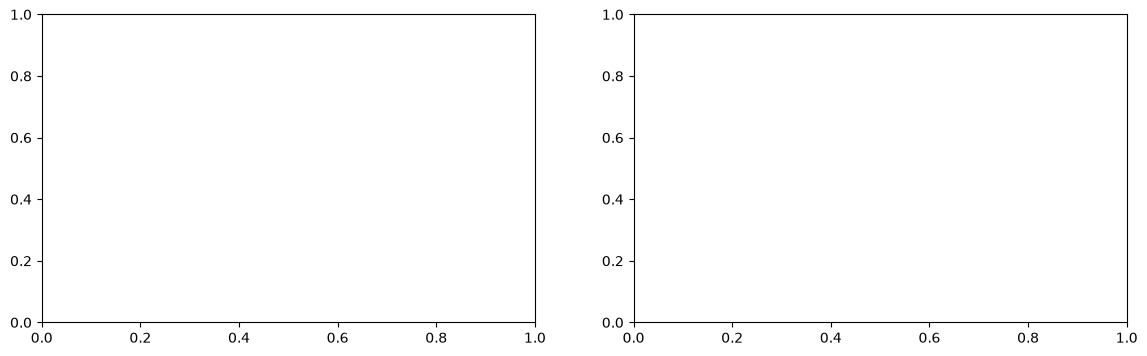

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(sweep.index, sweep["good_parts_per_shift"], marker="o", color="seagreen")
axes[0].axvline(best_threshold, color="red", linestyle="--", label=f"Best = {best_threshold}")
axes[0].set_title("Good Parts per Shift vs PM Threshold")
axes[0].set_xlabel("Do PM when health drops below (%)")
axes[0].legend()

axes[1].plot(sweep.index, sweep["failures"], marker="o", color="crimson", label="Breakdowns")
axes[1].plot(sweep.index, sweep["pm_count"], marker="o", color="steelblue", label="Planned maintenances")
axes[1].set_title("Breakdowns vs Planned Maintenance")
axes[1].set_xlabel("Do PM when health drops below (%)")
axes[1].legend()

plt.tight_layout()
plt.savefig("../images/04_pm_threshold.png", dpi=120)
plt.show()

### Business case (example numbers)
For each scenario:

$$\text{extra profit} = (\text{good/shift}_{\text{scenario}} - \text{good/shift}_{\text{baseline}}) \times \$20$$

$$\text{net gain/shift} = \text{extra profit} - \text{extra cost}$$

The scenario with the highest net gain is the best investment. The most output isn't always the best value.

In [ ]:
PROFIT_PER_GOOD_PART = 20        # $ profit from each good part

# Extra cost per shift for each scenario (example numbers, change them if you like)
EXTRA_COST_PER_SHIFT = {
    "1. Baseline":               0,
    "2. Second welder":          150,   # machine lease + operator
    "3. Faster welder (4.5min)": 100,   # a more expensive machine
    "4. Preventive maintenance": 40,    # technician time + spare parts
    "5. Faster repairs":         120,   # a bigger repair team
    "6. 2nd welder + PM":        190,
}

business = results[["good_parts_per_shift", "vs_baseline_%"]].copy()
business["extra_cost_$"] = pd.Series(EXTRA_COST_PER_SHIFT)
business["extra_profit_$"] = (business["good_parts_per_shift"] - baseline_good) * PROFIT_PER_GOOD_PART
business["net_gain_per_shift_$"] = business["extra_profit_$"] - business["extra_cost_$"]

best = business["net_gain_per_shift_$"].idxmax()
print(f"🏆 Best investment: {best}  (net gain ≈ ${business.loc[best, 'net_gain_per_shift_$']:.0f} per shift)")
business.round(1)

## 📝 Conclusions
- The scenario with the most good parts is **2nd welder + PM: 85.4 parts/shift (+27%)**.
- The best-value investment is also **2nd welder + PM**, with a net gain of about **$174 per shift**. Of the single changes, the **faster welder** is best ($132/shift): it gives slightly more output than a second welder and costs less.
- The best PM threshold is **60%**. Below it, machines break before maintenance happens. Above it, they stop for maintenance too often: at 90%, output drops back to the baseline level.
- Surprising results:
  - Extra welding capacity **increases breakdowns** (57.8 → 69.8). More parts flow through the line, so every machine wears faster.
  - PM's biggest effect is on **quality**: yield rises from 91.5% to 98.6%.
  - Faster repairs barely help (+4.3%) and lose money.
- My recommendation to the factory manager:
  1. Start preventive maintenance at 60% health right away. It is cheap ($40/shift) and gives +8% output and much better quality.
  2. Then fix the bottleneck. Test **faster welder + PM** next, because the faster welder beat the second welder on its own.